In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy

# Load dataset
df = pd.read_csv("fakenews.csv")

# Display first five rows
print(df.head())

# Check dataset information
print(df.info())

   news_id                                    headline  \
0        1              Global economy faces recession   
1        2   Earthquake hits Chittagong, panic spreads   
2        3  Breakthrough in Bangladesh's tech industry   
3        4     Dengue situation worsens in the country   
4        5              New virus outbreak sparks fear   

                                           body_text      source label  
0  The Prime Minister attended the inauguration c...         CNN  Real  
1  Government sources state that an official anno...  Daily Star  Real  
2  Local administration has visited the spot for ...         BBC  Fake  
3  The Prime Minister attended the inauguration c...         BBC  Fake  
4  Government sources state that an official anno...     Reuters  Real  
<class 'pandas.DataFrame'>
RangeIndex: 2212 entries, 0 to 2211
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   news_id    2212 non-null   int64
 1  

In [2]:
# Load the English language model
nlp = spacy.load("en_core_web_sm")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display the combined text
print(df[["label", "text"]].head())

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [4]:
# POS tagging on each article
pos_results = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    for token in doc:
        if not token.is_space and not token.is_punct:
            pos_results.append({
                "news_id": row["news_id"],
                "label": row["label"],
                "word": token.text,
                "POS_tag": token.pos_,
                "detailed_tag": token.tag_
            })

# Convert results into a DataFrame
pos_df = pd.DataFrame(pos_results)

# Display the first 20 tagged words
print(pos_df.head(20))


    news_id label          word POS_tag detailed_tag
0         1  Real        Global     ADJ           JJ
1         1  Real       economy    NOUN           NN
2         1  Real         faces    VERB          VBZ
3         1  Real     recession    NOUN           NN
4         1  Real           The     DET           DT
5         1  Real         Prime   PROPN          NNP
6         1  Real      Minister   PROPN          NNP
7         1  Real      attended    VERB          VBD
8         1  Real           the     DET           DT
9         1  Real  inauguration    NOUN           NN
10        1  Real      ceremony    NOUN           NN
11        1  Real            as     ADP           IN
12        1  Real           the     DET           DT
13        1  Real         chief     ADJ           JJ
14        1  Real         guest    NOUN           NN
15        2  Real    Earthquake    NOUN           NN
16        2  Real          hits    VERB          VBZ
17        2  Real    Chittagong   PROPN       

In [5]:
# Selecting important POS categories
selected_pos = [
    "NOUN", "PROPN", "VERB", "AUX",
    "ADJ", "ADV", "PRON", "DET",
    "ADP", "CCONJ", "SCONJ", "NUM"
]

# Calculate POS frequency for each news label
pos_frequency = pos_df.groupby(
    ["label", "POS_tag"]
).size().unstack(fill_value=0)

# Keep selected POS categories
pos_frequency = pos_frequency.reindex(
    columns=selected_pos, fill_value=0
)

# Display comparison
print("POS Frequency Comparison: Real vs Fake News")
print(pos_frequency)

POS Frequency Comparison: Real vs Fake News
POS_tag  NOUN  PROPN  VERB   AUX   ADJ  ADV  PRON   DET   ADP  CCONJ  SCONJ  \
label                                                                         
Fake     5181   1604  2974  1101  1785  528   443  1915  1488      0    225   
Real     5029   1604  2961  1055  1827  542   442  1882  1425      0    199   

POS_tag  NUM  
label         
Fake       0  
Real       0  


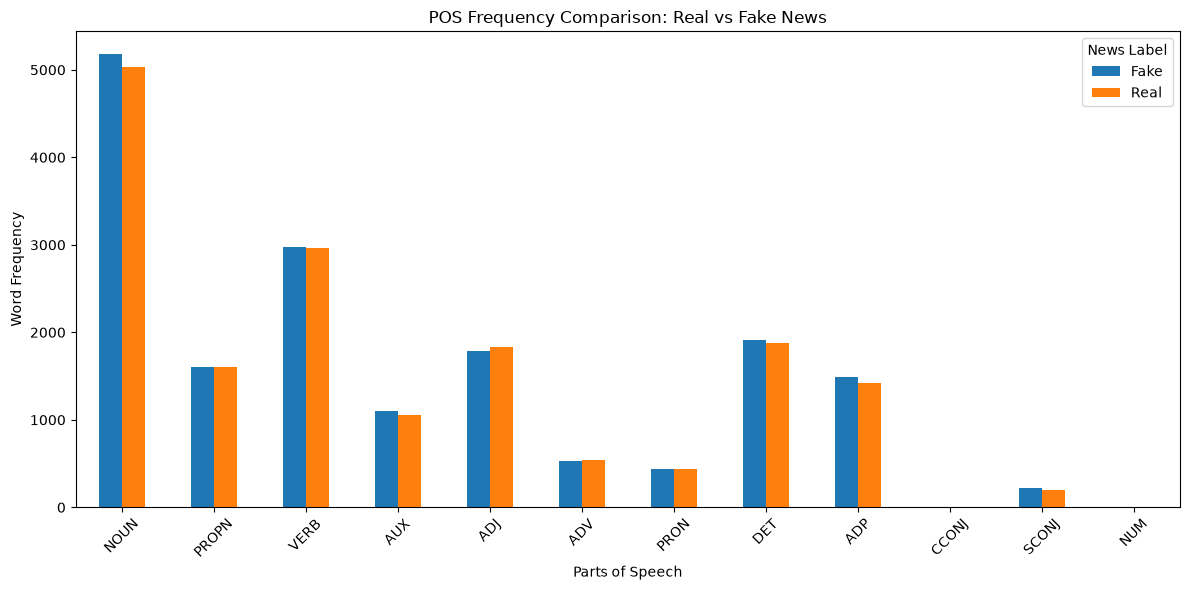

In [6]:
# Plot POS frequency comparison
pos_frequency.T.plot(kind="bar", figsize=(12, 6))

plt.title("POS Frequency Comparison: Real vs Fake News")
plt.xlabel("Parts of Speech")
plt.ylabel("Word Frequency")
plt.xticks(rotation=45)
plt.legend(title="News Label")
plt.tight_layout()

# Save graph
plt.savefig("T13_pos_frequency_comparison.png")
plt.show()

In [7]:

# Save POS frequency comparison
pos_frequency.to_csv("T13_pos_frequency_by_label.csv")

# Save detailed POS tagging results
pos_df.to_csv("T13_pos_tagged_tokens.csv", index=False)

print("Files saved successfully!")
print("1. T13_pos_frequency_by_label.csv")
print("2. T13_pos_tagged_tokens.csv")


Files saved successfully!
1. T13_pos_frequency_by_label.csv
2. T13_pos_tagged_tokens.csv
